# Replicando o Sean

> Sean Carlisto De Alvarenga, Sylvio Barbon, Rodrigo Sanches Miani, Michel Cukier, e Bruno Bogaz Zarpelão. "***Process Mining and Hierarchical Clustering to Help Intrusion Alert Visualization***". Computers & Security 73 (março de 2018): 474–91. https://doi.org/10.1016/j.cose.2017.11.021.

<font size="4">O Sean escolhe dias pelo ano todo. Nele, não há "cenários"</font>

<font size="4">Aqui temos 10 dias (LAB - 16-25/nov) + 23 dias (REAL - 27/jun a 20/jul)</font>

<font size="4">Sendo assim, agregaremos juntando *ambos* os cenários</font>

<font size="4">"Alertas" COMISET = linhas com rótulo MITRE (~1,7M no LAB, ~630k no REAL)</font>

<font size="4">Filtro do Sean = Grupos com só 1 alerta ou todos iguais são descartados (só multi-fase)</font>

<font size="4">Ressalva técnica (*se* for clusterizar): Ward pressupõe distância euclidiana, Jaccard não é. Sean usou assim mesmo, aqui faremos igual.</font>

# Imports e Configs

In [1]:
%xmode plain
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

Exception reporting mode: Plain


In [2]:
import os
import time

from pathlib import Path

import duckdb

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from pprint import pprint
from collections import Counter

import graphviz

import psutil
import shutil

import platform

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

In [3]:
%load_ext autoreload
%autoreload 2

> Algumas facilidades

In [4]:
from util import cron, salvar

# Conexão DuckDB

In [5]:
total_cpus = psutil.cpu_count(logical=True)
total_memory_gb = psutil.virtual_memory().total / (1024 ** 3)
total_memory_gb_rounded = round(total_memory_gb, 0)
print(f"CPUs (Lógicos):    {total_cpus}")
print(f"Memória RAM Total: {total_memory_gb_rounded} GB")

CPUs (Lógicos):    16
Memória RAM Total: 32.0 GB


In [6]:
conn = duckdb.connect()
conn.execute(f"SET threads = {total_cpus - 1}")
conn.execute(f"SET memory_limit = '{total_memory_gb_rounded - 2}GB'")

In [7]:
conn.sql("""
    SELECT name, value
    FROM duckdb_settings()
    WHERE name IN (
      'threads', 'memory_limit'
    )
""").show()

┌──────────────┬──────────┐
│     name     │  value   │
│   varchar    │ varchar  │
├──────────────┼──────────┤
│ memory_limit │ 27.9 GiB │
│ threads      │ 15       │
└──────────────┴──────────┘



#  Caminho de saída dos artefatos

In [8]:
RAW = {
    "lab": Path("dados/lab_events.parquet"),
    "real": Path("dados/real_events.parquet"),
}
OUT = Path("saidas/sean")  # artefatos deste notebook
OUT.mkdir(exist_ok=True)

# Nomes Sysmon

In [9]:
# https://learn.microsoft.com/en-us/sysinternals/downloads/sysmon#events
SYSMON = {
    1: "ProcessCreate",
    2: "FileCreateTime",
    3: "NetworkConnect",
    4: "SysmonServiceState",
    5: "ProcessTerminate",
    6: "DriverLoad",
    7: "ImageLoad",
    8: "CreateRemoteThread",
    9: "RawAccessRead",
    10: "ProcessAccess",
    11: "FileCreate",
    12: "RegistryCreateDelete",
    13: "RegistrySetValue",
    14: "RegistryRename",
    15: "FileCreateStreamHash",
    16: "SysmonConfigChange",
    17: "PipeCreated",
    18: "PipeConnected",
    19: "WmiEventFilter",
    20: "WmiEventConsumer",
    21: "WmiConsumerBinding",
    22: "DnsQuery",
    23: "FileDelete",
    24: "ClipboardChange",
    25: "ProcessTampering",
    26: "FileDeleteDetected",
    27: "FileBlockExecutable",
    28: "FileBlockShredding",
    29: "FileExecutableDetected",
    255: "Error",
}

# 1. Alertas

<font size="4">O Sean parte de alertas gerados por IDS</font>

<font size="4">Aqui consideraremos alertas = eventos com regra Sysmon (`rule_technique_id` presente)</font>

<font size="4">Selecionamos só alertas, de todos os dias, de colunas pertinentes (<b>ao todo 16</b>)</font>

<font size="4">Tal agregação já poderia servir como um "achatamento à la Sean"</font>

> Importante: Direção dos IPs

<font size="4">Sean usa tráfego de entrada, então o `src_ip` é o atacante</font>

<font size="4">Aqui, no Sysmon, o `src_ip` é o alvo. Temos que verificar a direção</font>

<font size="4">O campo `Initiated` tem que ser `false` = conexão veio de fora</font>

In [10]:
# chave inexistente no MAP (`_source` da tabela duckdb) vira NULL (cf. cobertura logo abaixo)
# "nome_nosso" : "nome_original"
CAMPOS = {
    "host":               "host_name",
    "technique_id":       "rule_technique_id",
    "technique_name":     "rule_technique_name",
    "rule":                "RuleName",
    "usr":                "user_name",
    "proc_guid":          "process_guid",
    "proc_name":          "process_name",
    "proc_path":          "process_path",
    "proc_parent_guid":   "process_parent_guid",
    "proc_parent_name":   "process_parent_name",
    "tgt_proc_guid":      "target_process_guid",
    "tgt_proc_name":      "target_process_name",
    "src_ip":             "src_ip_addr",
    "dst_ip":             "dst_ip_addr",
    "dst_port":           "DestinationPort",
    "initiated":          "Initiated",
}

In [13]:
len(CAMPOS.keys())

16

In [14]:
def sql_alertas(cenario):
    """Gera o texto SQL pra um dado cenário"""
    # json_extract_string tira as aspas e decodifica os escapes (\\ -> \)
    cols = ",\n        ".join(
        f"""json_extract_string(_source['{k}'], '$') AS "{a}" """
        for a, k in CAMPOS.items()
    )
    return f"""
    SELECT
        _id,
        split_part(_index, '-', 4) AS canal,
        try_cast(json_extract_string(_source['@timestamp'], '$') AS TIMESTAMP) AS ts,
        try_cast(json_extract_string(_source['event_id'], '$') AS INTEGER)     AS event_id,
        {cols}
    FROM read_parquet('{RAW[cenario]}')
    WHERE _source['rule_technique_id'] IS NOT NULL
    """

In [15]:
print(sql_alertas("lab"))


    SELECT
        _id,
        split_part(_index, '-', 4) AS canal,
        try_cast(json_extract_string(_source['@timestamp'], '$') AS TIMESTAMP) AS ts,
        try_cast(json_extract_string(_source['event_id'], '$') AS INTEGER)     AS event_id,
        json_extract_string(_source['host_name'], '$') AS "host" ,
        json_extract_string(_source['rule_technique_id'], '$') AS "technique_id" ,
        json_extract_string(_source['rule_technique_name'], '$') AS "technique_name" ,
        json_extract_string(_source['RuleName'], '$') AS "rule" ,
        json_extract_string(_source['user_name'], '$') AS "usr" ,
        json_extract_string(_source['process_guid'], '$') AS "proc_guid" ,
        json_extract_string(_source['process_name'], '$') AS "proc_name" ,
        json_extract_string(_source['process_path'], '$') AS "proc_path" ,
        json_extract_string(_source['process_parent_guid'], '$') AS "proc_parent_guid" ,
        json_extract_string(_source['process_parent_name'], '$') AS "

In [16]:
# lento: varredura full do arquivo bruto, pros 2 cenários
# feita só uma vez, dps confere se já existe o arquivo
for cen in ["lab", "real"]:
    dst = OUT / f"alertas_{cen}.parquet"
    if dst.exists():
        print(f"'{dst}' já existe, pulando")
        continue
    with cron(f"extração {cen}"):
        conn.execute(
            f"COPY ({sql_alertas(cen)}) TO '{dst}' (FORMAT PARQUET, CODEC 'ZSTD')"
        )

'Sean\alertas_lab.parquet' já existe, pulando
'Sean\alertas_real.parquet' já existe, pulando


# 1.1 Conferência com os dados
> Esperado: 1.713.709 (lab) e 631.606 (real)

> Números dos cenários:

LAB
* `maliciosos_lab   =  1_713_709`
* `total_linhas_lab =  49_914_325`
* `proporção_lab    =  3,43%`

REAL
* `maliciosos_real   = 631_606`
* `total_linhas_real = 202_304_794`
* `proporção_real    = 0,31%`

> Somando pra obter o N total desse notebook

* `maliciosos = 1_713_709   + 631_606     = 2.345.315`
* `total      = 49_914_325  + 202_304_794 = 252.219.119`

> `alertas` é um dict com dois elementos, um de cada cenário. As chaves são o nome do *cenário* e os valores são *dataframes* (os df's dos alertas)

In [18]:
alertas = {
    c: pd.read_parquet(OUT / f"alertas_{c}.parquet", dtype_backend="pyarrow")
    for c in ["lab", "real"]
}
for c, df in alertas.items():
    print(
        f"{c:5s} {len(df):>10,} alertas | ts inválidos: {df['ts'].isna().sum()} | "
        f"hosts: {df['host'].nunique():>2} | {df['ts'].min().strftime('%d/%m/%Y')} a {df['ts'].max().strftime('%d/%m/%Y')}"
    )

lab    1,713,709 alertas | ts inválidos: 0 | hosts:  1 | 16/11/2022 a 25/11/2022
real     631,606 alertas | ts inválidos: 0 | hosts: 15 | 27/06/2022 a 20/07/2022


> Ao todo, temos **20 colunas** pois são as 16 do dict `CAMPOS` + 4 (_id, canal, ts, event_id)

In [19]:
alertas["lab"].head(2)
alertas["lab"].shape

,_id,canal,ts,event_id,host,technique_id,technique_name,rule,usr,proc_guid,proc_name,proc_path,proc_parent_guid,proc_parent_name,tgt_proc_guid,tgt_proc_name,src_ip,dst_ip,dst_port,initiated
0,f70944eb67850c34d55c4f120e0abbcc99d3410c,sysmon,2022-11-16 19:59:51.007000,12,desktop-4pvps6e.phoenix.local,T1553.004,Install Root Certificate,"technique_id=T1553.004,technique_name=Install ...",louis,4FD6B357-412E-6375-CA00-000000002900,onedrive.exe,c:\users\louis\appdata\local\microsoft\onedriv...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,4a72999a2c943dea5e7694192dcb22a289ccffb4,sysmon,2022-11-16 19:59:50.377000,7,desktop-4pvps6e.phoenix.local,T1574.002,DLL Side-Loading,"technique_id=T1574.002,technique_name=DLL Side...",louis,4FD6B357-412E-6375-CA00-000000002900,onedrive.exe,c:\users\louis\appdata\local\microsoft\onedriv...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


(1713709, 20)

In [20]:
alertas["real"].head(2)
alertas["real"].shape

,_id,canal,ts,event_id,host,technique_id,technique_name,rule,usr,proc_guid,proc_name,proc_path,proc_parent_guid,proc_parent_name,tgt_proc_guid,tgt_proc_name,src_ip,dst_ip,dst_port,initiated
0,5b500a180e4bbf4fb6368bb65e3b5878ca17342b,sysmon,2022-06-27 06:54:22.310000,7,computer15.domain.es,T1055,Process Injection,"technique_id=T1055,technique_name=Process Inje...",system,89c3ec89-541e-62b9-600d-000000008200,tc.exe,c:\program files\common files\siemens\automati...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
1,0444eb0b3fa45a2f22db2f4eb47ec69d96954f22,sysmon,2022-06-27 06:54:25.590000,7,computer15.domain.es,T1055,Process Injection,"technique_id=T1055,technique_name=Process Inje...",system,89c3ec89-5421-62b9-610d-000000008200,tc.exe,c:\program files\common files\siemens\automati...,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


(631606, 20)

# 1.2 Cobertura dos campos nos "Alertas"
> Dos 20 campos que temos, qual a % presente deles nos alertas que acabamos de construir?

In [21]:
# `alertas` é um dict com dois elementos, um de cada cenário
# as chaves são o nome do cenário e os valores são dataframes (os df's dos alertas)
cob = pd.DataFrame({c: df.notna().mean() * 100 for c, df in alertas.items()}).T
cob
cob.shape

,_id,canal,ts,event_id,host,technique_id,technique_name,rule,usr,proc_guid,proc_name,proc_path,proc_parent_guid,proc_parent_name,tgt_proc_guid,tgt_proc_name,src_ip,dst_ip,dst_port,initiated
lab,100.00,100.00,100.00,100.00,100.00,100.00,99.99,100.00,95.53,100.00,100.00,100.00,0.26,0.26,4.47,4.47,68.62,68.62,68.62,68.62
real,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,91.44,100.00,100.00,100.00,0.55,0.55,8.56,8.56,0.27,0.27,0.27,0.27


(2, 20)

> Quantos valores faltantes em cada campo?

In [45]:
pd.DataFrame(alertas["lab"].isna().sum().sort_values()).map("{:,}".format).T

,_id,canal,ts,event_id,host,technique_id,rule,proc_guid,proc_path,proc_name,technique_name,usr,initiated,dst_port,dst_ip,src_ip,tgt_proc_guid,tgt_proc_name,proc_parent_guid,proc_parent_name
0,0,0,0,0,0,0,0,0,0,0,162,"76,604","537,712","537,712","537,712","537,712","1,637,106","1,637,106","1,709,330","1,709,330"


In [51]:
cob[["src_ip", "dst_ip"]].map("{:.2f}%".format)

,src_ip,dst_ip
lab,68.62%,68.62%
real,0.27%,0.27%


> Qual a presença dos campos por EID? E qual o volume de cada EID?

In [52]:
# cada EID (tipo de evento Sysmon) tem campos diferentes
ORIG_DEST = ["proc_guid", "tgt_proc_guid", "proc_parent_guid", "usr", "src_ip", "dst_ip", "initiated"]

def cob_eid(df):
    cobertura = df.groupby("event_id")[ORIG_DEST].agg(lambda coluna: coluna.notna().mean() * 100)
    cobertura.insert(0, "n", df.groupby("event_id").size())
    cobertura.insert(0, "eid_name", cobertura.index.map(SYSMON))
    cobertura = cobertura.sort_values(by="n")
    cobertura["n"] = cobertura["n"].map("{:,d}".format)
    return cobertura

In [53]:
cob_eid(alertas["lab"])

,eid_name,n,proc_guid,tgt_proc_guid,proc_parent_guid,usr,src_ip,dst_ip,initiated
event_id,,,,,,,,,
18,PipeConnected,107,100.00,0.00,0.00,100.00,0.00,0.00,0.00
15,FileCreateStreamHash,199,100.00,0.00,0.00,100.00,0.00,0.00,0.00
1,ProcessCreate,"4,379",100.00,0.00,100.00,100.00,0.00,0.00,0.00
8,CreateRemoteThread,"6,422",100.00,100.00,0.00,0.00,0.00,0.00,0.00
7,ImageLoad,"27,988",100.00,0.00,0.00,100.00,0.00,0.00,0.00
10,ProcessAccess,"70,181",100.00,100.00,0.00,0.00,0.00,0.00,0.00
12,RegistryCreateDelete,"121,751",100.00,0.00,0.00,100.00,0.00,0.00,0.00
13,RegistrySetValue,"151,553",100.00,0.00,0.00,100.00,0.00,0.00,0.00
11,FileCreate,"155,132",100.00,0.00,0.00,100.00,0.00,0.00,0.00


In [54]:
cob_eid(alertas["real"])

,eid_name,n,proc_guid,tgt_proc_guid,proc_parent_guid,usr,src_ip,dst_ip,initiated
event_id,,,,,,,,,
18,PipeConnected,1,100.00,0.00,0.00,100.00,0.00,0.00,0.00
11,FileCreate,4,100.00,0.00,0.00,100.00,0.00,0.00,0.00
2,FileCreateTime,44,100.00,0.00,0.00,100.00,0.00,0.00,0.00
15,FileCreateStreamHash,65,100.00,0.00,0.00,100.00,0.00,0.00,0.00
8,CreateRemoteThread,317,100.00,100.00,0.00,0.00,0.00,0.00,0.00
3,NetworkConnect,"1,676",100.00,0.00,0.00,99.88,100.00,100.00,100.00
1,ProcessCreate,"3,457",100.00,0.00,100.00,100.00,0.00,0.00,0.00
13,RegistrySetValue,"18,672",100.00,0.00,0.00,100.00,0.00,0.00,0.00
12,RegistryCreateDelete,"29,793",100.00,0.00,0.00,100.00,0.00,0.00,0.00


# 1.3 IPs

> Quantos IPs distintos e quais suas direções?

In [55]:
for c, df in alertas.items():
    ip = df[df["src_ip"].notna()]
    pares = ip[["src_ip", "dst_ip"]].drop_duplicates()
    
    print(
        f"\n{"="*50}\n"
        f"{c.upper()}: {len(ip):,} alertas com IP ({len(ip) / len(df):.1%}) \n"
        f"src distintos: {ip['src_ip'].nunique()} \n"
        f"dst distintos: {ip['dst_ip'].nunique()} \n"
        f"pares src-dst: {len(pares)}"
    )

    print("\n===Direção===")
    display(ip["initiated"].value_counts(dropna=False))   # direção
    print("\n===Top 10 Origem===")
    display(ip["src_ip"].value_counts().head(10))         # quem mais aparece como origem
    print("\n===Top 10 Processos Iniciadores===")
    display(ip["proc_name"].value_counts().head(10))      # que processo faz as conexões


LAB: 1,175,997 alertas com IP (68.6%) 
src distintos: 57 
dst distintos: 154 
pares src-dst: 340

===Direção===


initiated
true     1175410
false        587
Name: count, dtype: int64[pyarrow]


===Top 10 Origem===


src_ip
192.168.137.132    420144
192.168.47.142     325887
192.168.182.131    121669
192.168.137.131     97631
192.168.47.147      76820
192.168.235.150     29939
192.168.137.148     18401
192.168.253.141     15619
192.168.50.131       8584
192.168.253.135      7644
Name: count, dtype: int64[pyarrow]


===Top 10 Processos Iniciadores===


...

initiated
true     1442
false     234
Name: count, dtype: int64[pyarrow]


===Top 10 Origem===


src_ip
192.168.194.132    556
127.0.0.1          206
172.20.2.109       198
172.20.2.116       135
172.20.2.115        95
172.20.2.105        82
172.20.2.110        61
172.20.2.117        60
172.20.2.112        59
172.20.2.106        45
Name: count, dtype: int64[pyarrow]


===Top 10 Processos Iniciadores===


proc_name
printerserviceserverconsole.exe    338
msmpeng.exe                        311
nslookup.exe                       217
powershell.exe                     175
su-repair.exe                      162
cmd.exe                            153
gc_print_data_service.exe          124
sophosupdate.exe                   111
certutil.exe                        20
sqlceip.exe                         11
Name: count, dtype: int64[pyarrow]

> **Quase não há tráfego de entrada: 587 (de 1,175,997) no LAB, e 234 (de 1,676) no REAL**

> **A replicação literal vai trabalhar com muito pouco dado.**

# 1.4 Direção do tráfego
> Sean usa só tráfego de entrada (de fora pra dentro, *inbound*).

> Quem são as origens de entrada e quais serviços (portas) são alvo?

In [56]:
for c, df in alertas.items():
    ip = df[df["src_ip"].notna()]
    print(f"\n{c.upper()}  (false = entrada, true = saída)")
    display(
        ip.groupby("initiated").agg(
            alertas=("src_ip", "size"),
            src=("src_ip", "nunique"),
            dst=("dst_ip", "nunique"),
            portas=("dst_port", "nunique"),
        )
    )
    entrada = ip[ip["initiated"] == "false"]
    entrada.value_counts(["src_ip", "dst_ip", "dst_port", "proc_name"])


LAB  (false = entrada, true = saída)


,alertas,src,dst,portas
initiated,,,,
false,587,20,13,16
true,1175410,39,143,52


src_ip           dst_ip           dst_port  proc_name                
10.10.234.120    10.10.234.129    3389      svchost.exe                  239
10.10.234.128    10.10.234.129    3389      svchost.exe                   90
127.0.0.1        127.0.0.1        6000      xwin_mobax.exe                36
10.10.234.1      10.10.234.129    3389      svchost.exe                   35
10.10.234.131    10.10.234.129    3389      svchost.exe                   35
192.168.182.128  192.168.182.131  3389      svchost.exe                   22
10.10.234.133    10.10.234.129    3389      svchost.exe                   20
192.168.16.128   192.168.16.130   3389      svchost.exe                   16
10.10.117.130    10.10.117.130    3389      svchost.exe                   14
192.168.5.139    192.168.5.137    3389      svchost.exe                   14
192.168.16.133   192.168.16.132   3389      svchost.exe                    9
192.168.253.129  192.168.253.141  3389      svchost.exe                    7
192.16


REAL  (false = entrada, true = saída)


,alertas,src,dst,portas
initiated,,,,
false,234,2,2,95
true,1442,17,84,225


src_ip           dst_ip         dst_port  proc_name                      
192.168.194.132  192.168.194.2  53        nslookup.exe                       80
                                          cmd.exe                            54
127.0.0.1        127.0.0.1      4536      printerserviceserverconsole.exe     7
                                4709      gc_print_data_service.exe           1
                                33523     gc_print_data_service.exe           1
                                                                             ..
                                1638      gc_print_data_service.exe           1
                                1628      gc_print_data_service.exe           1
                                1630      gc_print_data_service.exe           1
                                1632      gc_print_data_service.exe           1
                                1640      gc_print_data_service.exe           1
Name: count, Length: 96, dtype: int64

> `nslookup` é client DNS, então marcar como "entrada" é estranho

> A direção do Sysmon é conhecida por ser pouco confiável em UDP

# 1.5 Aside: Por que tantos IPs de Origem no LAB?

> Os 57 IPs de origem do LAB: as sub-redes mudam por dia? (hipótese: VMs em redes diferentes por sessão)

In [57]:
with cron("crosstab pra detectar sub-redes diferentes ao longo dos dias/sessões"):
    lab = alertas["lab"]
    saida = lab[lab["initiated"] == "true"]
    rede = saida["src_ip"].str.extract(r"^(?P<rede>\d+\.\d+\.\d+)\.", expand=False)   # os 3 primeiros blocos do IP
    pd.crosstab(saida["ts"].dt.strftime("%d/%m"), rede)

rede,10.10.117,10.10.234,127.0.0,192.168.137,192.168.16,192.168.182,192.168.21,192.168.232,192.168.235,192.168.253,192.168.47,192.168.5,192.168.50,192.168.75,192.168.88
ts,,,,,,,,,,,,,,,
16/11,4,8,21,97630,0,0,0,3,0,324,77,0,0,2,86
17/11,6,0,9,18165,15,0,0,0,0,2236,325809,367,0,2,2874
18/11,51,165,9,773,10,109500,49,16,0,12273,3592,0,0,4000,1040
19/11,131,2,10,1778,2,3833,1223,0,24008,0,8152,0,0,0,12801
20/11,53,2,4,269430,0,129,7480,0,0,0,68668,0,0,2699,270
21/11,10,0,3,148936,1,4161,280,0,323,0,0,0,6,0,0
22/11,0,0,0,0,37,4046,0,0,1017,0,0,0,0,0,1
23/11,4,0,0,53,415,0,0,0,3890,0,0,0,0,0,0
24/11,52,0,0,180,871,0,0,0,0,14139,0,2402,5128,0,0



[tempo] crosstab pra detectar sub-redes diferentes ao longo dos dias/sessões: 7.6s



# 2. Higiene das técnicas
IDs sujos ("1210", "T", "Port Monitors") e de versões antigas do ATT&CK (por ex., real usa T1130 e lab T1553.004 pra a mesma coisa)

> Pra entender esse regex com capture group nomeado (o `P` é de Python)

In [58]:
alertas["lab"]["rule"][1]

'technique_id=T1574.002,technique_name=DLL Side-Loading'

In [59]:
# `expand=True` faria retornar um DataFrame com uma coluna com o nome do capture group
with cron("regex mais pesado"):
    alertas["lab"]["rule"].str.extract(r"technique_id=(?P<tid>[^,]+)", expand=False)
    alertas["real"]["rule"].str.extract(r"technique_id=(?P<tid>[^,]+)", expand=False)

0          T1553.004
1          T1574.002
2          T1574.002
3          T1055.001
4          T1055.001
             ...    
1713704    T1055.001
1713705        T1055
1713706        T1055
1713707        T1055
1713708        T1543
Name: tid, Length: 1713709, dtype: string[pyarrow]

0         T1055
1         T1055
2         T1055
3         T1055
4         T1055
          ...  
631601    T1055
631602    T1055
631603    T1055
631604    T1055
631605    T1055
Name: tid, Length: 631606, dtype: string[pyarrow]


[tempo] regex mais pesado: 0.5s



> Conferir ID contra o RuleName

In [60]:
for c, df in alertas.items():
    df["technique_id_rule"] = df["rule"].str.extract(r"technique_id=(?P<tid>[^,]+)", expand=False)
    dif = df["technique_id"].ne(df["technique_id_rule"]).fillna(True)
    print(f"{c.upper():>4}: {dif.sum():,} alertas com `technique_id` diferente do RuleName")

 LAB: 0 alertas com `technique_id` diferente do RuleName
REAL: 0 alertas com `technique_id` diferente do RuleName


> Quem dispara os IDs suspeitos?

In [61]:
SUSPEITOS = ["T", "T1064", "T1175", "T1089"]
# T     -> sem número
# T1064 -> técnica deprecated
# T1175 -> ambíguo entre COM e DCOM
# T1089 -> ID e nome não batiam

for c, df in alertas.items():
    s = df[df["technique_id"].isin(SUSPEITOS)]
    print(f"========== Cenário: {c.upper():>4} ==========")
    s.value_counts(["technique_id", "technique_name", "event_id", "proc_name"])
    print()

========== Cenário:  LAB ==========


Series([], Name: count, dtype: int64)


========== Cenário: REAL ==========


technique_id  technique_name                              event_id  proc_name                      
T1175         Component Object Model and Distributed COM  7         sdxhelper.exe                      39
T1089         Drive-by Compromise                         15        explorer.exe                       25
                                                                    chrome.exe                         19
T1175         Component Object Model and Distributed COM  7         msoia.exe                          11
T1064         Scripting                                   11        pwsh.exe                            3
              Windows Scripting Host Component            7         wscript.exe                         3
T1089         Drive-by Compromise                         15        firefox.exe                         2
T1064         Windows Scripting Host Component            7         regsvr32.exe                        2
T1175         Component Object Model and Distributed

> Dicionário de correção

In [73]:
# ID sujo ou antigo -> ID atual
FIX = {
    "1210": "T1210",
    "Port Monitors": "T1547.010",
    "T1546.0082": "T1546.008",
    "T1547.0102": "T1547.010",
    "T1055; Possible Cobalt Strike post-exploitation jobs.": "T1055",
    "T1086": "T1059.001",  # PowerShell
    "T1093": "T1055.012",  # Process Hollowing
    "T1130": "T1553.004",  # Install Root Certificate
    "T1073": "T1574.002",  # DLL Side-Loading
    "T1099": "T1070.006",  # Timestomp
    "T1170": "T1218.005",  # Mshta
    "T1117": "T1218.010",  # Regsvr32
    "T1063": "T1518.001",  # Security Software Discovery
    "T1031": "T1543.003",  # Modify Existing Service
    "T1064": "T1059.005",  # Scripting -> Visual Basic (wscript/cscript)                ; cf. acima
    "T1175": "T1559.001",  # COM (se for DCOM seria T1021.003)                          ; cf. acima
    "T1089": "T1189",       # ID diz Disabling Security Tools, nome diz Drive-by (T1189) ; cf. acima
}

> Aplicação da correção e diferenças (oq sobrou). A nova coluna `technique` é o nome normalizado/corrigido

In [74]:
PADRAO = r"^T\d{4}(\.\d{3})?$"

In [75]:
with cron("regex e diferenças pós-correção rótulos MITRE"):
    for c, df in alertas.items():
        # como em 2. Higiene tivemos "0 alertas com `technique_id` diferente do RuleName" essas duas não precisamos mais
        # t = df["technique_id"].replace(FIX)
        # ok = t.str.match(PADRAO).fillna(False)
        df["technique"] = df["technique_id"].replace(FIX)                                        # normalizada: é a atividade
        df["technique_parent"] = df["technique"].str.extract(r"^(?P<pai>T\d{4})", expand=False)  # sem subtécnica
        sobra = df.loc[~df["technique"].str.match(PADRAO).fillna(False), "technique"].value_counts(dropna=False)
        print(
            f"{c.upper():>4}: {df['technique_id'].nunique()} -> {df['technique'].nunique()} técnicas "
            f"| {df['technique_parent'].nunique()} pais | fora do padrão: {sobra.to_dict()}"
        )
    
    a, b = (set(alertas[c]["technique_id"].dropna()) for c in ["lab", "real"])
    A, B = (set(alertas[c]["technique"].dropna()) for c in ["lab", "real"])
    print(f"\ntécnicas em comum LAB e REAL: {len(a & b)} -> {len(A & B)}")

 LAB: 53 -> 50 técnicas | 35 pais | fora do padrão: {'T': 55}
REAL: 57 -> 53 técnicas | 33 pais | fora do padrão: {'T': 1}

técnicas em comum LAB e REAL: 37 -> 40

[tempo] regex e diferenças pós-correção rótulos MITRE: 4.1s



> Sanity Check: Não perdemos nenhum alerta

In [76]:
f"{alertas["lab"].shape[0]:,}"
f"{alertas["real"].shape[0]:,}"

'1,713,709'

'631,606'

# 2.1 Salvando Alertas Limpos

In [162]:
arquivos = [
    OUT / f"alertas_{cenario}_limpo"
    for cenario in alertas
]

if not all(arquivo.exists() for arquivo in arquivos):
    with cron("salvar as duas possibilidades de alertas"):
        for cenario, alertas_cenario in alertas.items():
            # essa `salvar` vem do `from util import`
            salvar(alertas_cenario, OUT / f"alertas_{cenario}_limpo")
else:
    print("Todos os arquivos já existem. Pulando salvamento.")


[tempo] salvar as duas possibilidades de alertas: 21.5s



# 3. Construção do Event Log + Filtro

> Caso = `<IP_origem + dia>`

> Filtro: Descarta casos com apenas 1 técnica

> `entrada` é o literal do Sean (só tráfego de entrada); `todas` é sem filtro de direção, só pra comparar

> Alertas sem técnica válida ("T") são descartados

In [125]:
# valores do campo "initiated" aceitos em cada versão
DIRECOES = {"entrada": ["false"], "todas": ["true", "false"]}

In [128]:
# colunas que integrarão o event log
COLUNAS_DO_LOG = ["case", "ts", "dia", "src_ip", "dst_ip", "dst_port", "technique", "technique_name", "proc_name"]

In [129]:
with cron("construção do event log e filtragem"):
    event_logs = {}        # (cenário, direção) -> event log filtrado, cada linha é um "alerta"
    resumo_por_dia = {}    # (cenário, direção) -> alertas, IPs e técnicas por dia (antes do filtro)
    
    for cenario, alertas_cenario in alertas.items():
        for direcao, valores_initiated in DIRECOES.items():
    
            # 1. só alertas de rede, na direção escolhida, com técnica válida
            tem_ip = alertas_cenario["src_ip"].notna()
            na_direcao = alertas_cenario["initiated"].isin(valores_initiated)
            tecnica_valida = alertas_cenario["technique"].str.match(PADRAO).fillna(False)
            alertas_rede = alertas_cenario[tem_ip & na_direcao & tecnica_valida].copy()
    
            # 2. caso = IP de origem + dia
            alertas_rede["dia"] = alertas_rede["ts"].dt.strftime("%d/%m/%Y")
            alertas_rede["case"] = alertas_rede["src_ip"] + "|" + alertas_rede["dia"]
    
            # 3. resumo por dia, para escolher os dias como o Sean (5.1)
            resumo_por_dia[(cenario, direcao)] = alertas_rede.groupby("dia").agg(
                alertas=("technique", "size"),
                ips_distintos=("src_ip", "nunique"),
                tecnicas_distintas=("technique", "nunique"),
            )
    
            # 4. filtro do Sean: descarta casos com uma técnica só
            tecnicas_no_caso = alertas_rede.groupby("case")["technique"].transform("nunique")
            event_log = alertas_rede[tecnicas_no_caso > 1]
            event_log = event_log.sort_values(["case", "ts"], kind="stable")[COLUNAS_DO_LOG]
    
            event_logs[(cenario, direcao)] = event_log
            salvar(event_log, OUT / f"log_{cenario}_{direcao}")
    
            reducao = 1 - len(event_log) / max(len(alertas_rede), 1)
            print(
                f"{cenario:>4} {direcao:>7}: {len(alertas_rede):>9,} alertas -> {len(event_log):>7,} eventos "
                f"({reducao:.1%} de redução) | {event_log['case'].nunique():>2} casos "
                f"| {event_log['src_ip'].nunique():>2} IPs | {event_log['technique'].nunique()} atividades"
            )

 lab entrada:       587 alertas ->      14 eventos (97.6% de redução) |  3 casos |  2 IPs | 3 atividades
 lab   todas: 1,175,997 alertas -> 684,904 eventos (41.8% de redução) | 41 casos | 20 IPs | 5 atividades
real entrada:       234 alertas ->     134 eventos (42.7% de redução) |  1 casos |  1 IPs | 2 atividades
real   todas:     1,676 alertas ->     967 eventos (42.3% de redução) | 24 casos | 14 IPs | 7 atividades

[tempo] construção do event log e filtragem: 12.5s



In [130]:
event_logs["lab", "entrada"].sort_values(by="technique_name")
event_logs["lab", "entrada"].shape

,case,ts,dia,src_ip,dst_ip,dst_port,technique,technique_name,proc_name
18582,10.10.117.130|16/11/2022,2022-11-16 20:48:31.344000,16/11/2022,10.10.117.130,10.10.117.130,6000,T1036,Masquerading,xwin_mobax.exe
733122,10.10.117.130|18/11/2022,2022-11-18 11:34:26.564000,18/11/2022,10.10.117.130,10.10.117.130,6000,T1036,Masquerading,xwin_mobax.exe
743265,127.0.0.1|18/11/2022,2022-11-18 06:33:57.441000,18/11/2022,127.0.0.1,127.0.0.1,6000,T1036,Masquerading,xwin_mobax.exe
743266,127.0.0.1|18/11/2022,2022-11-18 06:33:57.441000,18/11/2022,127.0.0.1,127.0.0.1,6000,T1036,Masquerading,xwin_mobax.exe
743268,127.0.0.1|18/11/2022,2022-11-18 06:33:57.456000,18/11/2022,127.0.0.1,127.0.0.1,6000,T1036,Masquerading,xwin_mobax.exe
666509,127.0.0.1|18/11/2022,2022-11-18 11:15:55.541000,18/11/2022,127.0.0.1,127.0.0.1,40914,T1036,Masquerading,beacon.exe
666483,127.0.0.1|18/11/2022,2022-11-18 11:17:31.979000,18/11/2022,127.0.0.1,127.0.0.1,53716,T1036,Masquerading,beacon.exe
740253,127.0.0.1|18/11/2022,2022-11-18 19:53:02.338000,18/11/2022,127.0.0.1,127.0.0.1,6457,T1036,Masquerading,beacon_2.exe
736134,127.0.0.1|18/11/2022,2022-11-18 19:58:10.377000,18/11/2022,127.0.0.1,127.0.0.1,4444,T1036,Masquerading,beacon_tcp_localhost.exe
18586,10.10.117.130|16/11/2022,2022-11-16 20:48:33.735000,16/11/2022,10.10.117.130,10.10.117.130,3389,T1021,Remote Services,svchost.exe


(14, 9)

In [131]:
event_logs["real", "entrada"].sort_values(by="technique_name")

,case,ts,dia,src_ip,dst_ip,dst_port,technique,technique_name,proc_name
146043,192.168.194.132|05/07/2022,2022-07-05 17:56:13.010000,05/07/2022,192.168.194.132,192.168.194.2,53,T1016,System Network Configuration Discovery,nslookup.exe
147491,192.168.194.132|05/07/2022,2022-07-05 17:56:23.085000,05/07/2022,192.168.194.132,192.168.194.2,53,T1016,System Network Configuration Discovery,nslookup.exe
147501,192.168.194.132|05/07/2022,2022-07-05 17:56:33.215000,05/07/2022,192.168.194.132,192.168.194.2,53,T1016,System Network Configuration Discovery,nslookup.exe
146855,192.168.194.132|05/07/2022,2022-07-05 17:59:15.268000,05/07/2022,192.168.194.132,192.168.194.2,53,T1016,System Network Configuration Discovery,nslookup.exe
146404,192.168.194.132|05/07/2022,2022-07-05 17:59:15.277000,05/07/2022,192.168.194.132,192.168.194.2,53,T1016,System Network Configuration Discovery,nslookup.exe
...,...,...,...,...,...,...,...,...,...
147203,192.168.194.132|05/07/2022,2022-07-05 17:59:22.414000,05/07/2022,192.168.194.132,192.168.194.2,53,T1059.003,Windows Command Shell,cmd.exe
147218,192.168.194.132|05/07/2022,2022-07-05 17:59:22.807000,05/07/2022,192.168.194.132,192.168.194.2,53,T1059.003,Windows Command Shell,cmd.exe
146967,192.168.194.132|05/07/2022,2022-07-05 17:59:22.837000,05/07/2022,192.168.194.132,192.168.194.2,53,T1059.003,Windows Command Shell,cmd.exe
147217,192.168.194.132|05/07/2022,2022-07-05 17:59:22.866000,05/07/2022,192.168.194.132,192.168.194.2,53,T1059.003,Windows Command Shell,cmd.exe


# 3.1 Dias selecionados (5.1)
> Dia com mais alertas, mais IPs distintos e mais técnicas distintas

In [132]:
def dias_com_mais(resumo):
    return {coluna: resumo[coluna].idxmax() for coluna in resumo.columns}

In [133]:
resumo_lab_entrada = resumo_por_dia[("lab", "entrada")]
pprint(dias_com_mais(resumo_lab_entrada), indent=4)
resumo_lab_entrada

{   'alertas': '17/11/2022',
    'ips_distintos': '16/11/2022',
    'tecnicas_distintas': '18/11/2022'}


,alertas,ips_distintos,tecnicas_distintas
dia,,,
16/11/2022,111,8,2
17/11/2022,209,7,2
18/11/2022,84,8,3
19/11/2022,60,7,2
20/11/2022,19,8,2
21/11/2022,13,5,2
22/11/2022,21,3,1
23/11/2022,10,2,1
24/11/2022,45,7,1


In [134]:
resumo_lab_todas = resumo_por_dia[("lab", "todas")]
pprint(dias_com_mais(resumo_lab_todas), indent=4)
resumo_lab_todas

{   'alertas': '17/11/2022',
    'ips_distintos': '18/11/2022',
    'tecnicas_distintas': '18/11/2022'}


,alertas,ips_distintos,tecnicas_distintas
dia,,,
16/11/2022,98266,15,3
17/11/2022,349692,17,4
18/11/2022,131562,23,5
19/11/2022,52000,18,4
20/11/2022,348754,17,3
21/11/2022,153733,11,4
22/11/2022,5122,8,3
23/11/2022,4372,5,4
24/11/2022,22817,12,4


In [135]:
resumo_real_entrada = resumo_por_dia[("real", "entrada")]
pprint(dias_com_mais(resumo_real_entrada), indent=4)
resumo_real_entrada

{   'alertas': '05/07/2022',
    'ips_distintos': '05/07/2022',
    'tecnicas_distintas': '05/07/2022'}


,alertas,ips_distintos,tecnicas_distintas
dia,,,
05/07/2022,134,1,2
06/07/2022,31,1,1
07/07/2022,33,1,1
08/07/2022,36,1,1


In [136]:
resumo_real_todas = resumo_por_dia[("real", "todas")]
pprint(dias_com_mais(resumo_real_todas), indent=4)
resumo_real_todas

{   'alertas': '05/07/2022',
    'ips_distintos': '06/07/2022',
    'tecnicas_distintas': '05/07/2022'}


,alertas,ips_distintos,tecnicas_distintas
dia,,,
01/07/2022,6,5,1
03/07/2022,9,4,1
05/07/2022,578,7,5
06/07/2022,290,14,4
07/07/2022,253,13,3
08/07/2022,330,14,4
09/07/2022,53,11,2
10/07/2022,7,4,1
20/07/2022,60,7,1


In [137]:
linhas = []
for (cenario, direcao), event_log in event_logs.items():
    for criterio, dia in dias_com_mais(resumo_por_dia[(cenario, direcao)]).items():
        log_do_dia = event_log[event_log["dia"] == dia]
        linhas.append({
            "cenario": cenario, "direcao": direcao, "criterio": criterio, "dia": dia,
            "eventos": len(log_do_dia),
            "casos": log_do_dia["case"].nunique(),
            "atividades": log_do_dia["technique"].nunique(),
        })

tabela_dias = pd.DataFrame(linhas)
salvar(tabela_dias, OUT / "tabela_dias")
tabela_dias

,cenario,direcao,criterio,dia,eventos,casos,atividades
0,lab,entrada,alertas,17/11/2022,0,0,0
1,lab,entrada,ips_distintos,16/11/2022,2,1,2
2,lab,entrada,tecnicas_distintas,18/11/2022,12,2,3
3,lab,todas,alertas,17/11/2022,349280,8,4
4,lab,todas,ips_distintos,18/11/2022,122489,9,5
5,lab,todas,tecnicas_distintas,18/11/2022,122489,9,5
6,real,entrada,alertas,05/07/2022,134,1,2
7,real,entrada,ips_distintos,05/07/2022,134,1,2
8,real,entrada,tecnicas_distintas,05/07/2022,134,1,2
9,real,todas,alertas,05/07/2022,558,2,5


# 4. Modelos DFG

> Modelo = vértices (atividades) e arestas ("b vem logo depois de a"), com frequências + início e fim

> Complexidade: V $\leq$ 12 simples; V $\gt$ 25 complexo. No meio, complexo se $\frac{V}{E} \lt ts$ (com $ts$ sendo uma função de V)

In [138]:
def descobrir_modelo(event_log):
    """Algoritmo 1 do Sean. Devolve as frequências dos vértices e das arestas."""
    vertices, arestas = Counter(), Counter()
    for caso, eventos_do_caso in event_log.groupby("case", sort=False):
        sequencia = ["INÍCIO"] + eventos_do_caso["technique"].tolist() + ["FIM"]
        vertices.update(sequencia[1:-1])                      # INÍCIO e FIM não têm peso
        arestas.update(zip(sequencia[:-1], sequencia[1:]))    # pares consecutivos
    return vertices, arestas

In [139]:
V_MIN, V_MAX = 12, 25    # Sean, eq. 6

In [140]:
def limiar_ts(n_vertices):
    """Sean, eq. 5: regressão sobre 219 modelos classificados por um especialista."""
    return 0.0215 * n_vertices + 0.0165

In [141]:
def eh_complexo(n_vertices, n_arestas):
    simplicidade = n_vertices / n_arestas    # eq. 2
    if n_vertices <= V_MIN:
        return False
    if n_vertices > V_MAX:
        return True
    return simplicidade < limiar_ts(n_vertices)

In [142]:
modelos = {}   # (cenário, direção, dia) -> (vértices, arestas)
linhas = []    # lista de dicts, cada elemento um resumo do dia

for (cenario, direcao), event_log in event_logs.items():
    dias_escolhidos = sorted(set(dias_com_mais(resumo_por_dia[(cenario, direcao)]).values()))
    for dia in dias_escolhidos:
        log_do_dia = event_log[event_log["dia"] == dia]
        if log_do_dia.empty:
            continue
        vertices, arestas = descobrir_modelo(log_do_dia)
        n_vertices = len(vertices) + 2    # + INÍCIO e FIM, como no paper
        n_arestas = len(arestas)
        modelos[(cenario, direcao, dia)] = (vertices, arestas)
        linhas.append({
            "cenario": cenario, "direcao": direcao, "dia": dia,
            "vertices": n_vertices, "arestas": n_arestas,
            "simplicidade": round(n_vertices / n_arestas, 3),
            "limiar_ts": round(limiar_ts(n_vertices), 3),
            "complexo": eh_complexo(n_vertices, n_arestas),
        })

tabela_modelos = pd.DataFrame(linhas)
salvar(tabela_modelos, OUT / "tabela_modelos")
tabela_modelos

,cenario,direcao,dia,vertices,arestas,simplicidade,limiar_ts,complexo
0,lab,entrada,16/11/2022,4,3,1.33,0.10,False
1,lab,entrada,18/11/2022,5,9,0.56,0.12,False
2,lab,todas,17/11/2022,6,15,0.40,0.15,False
3,lab,todas,18/11/2022,7,23,0.30,0.17,False
4,real,entrada,05/07/2022,4,6,0.67,0.10,False
5,real,todas,05/07/2022,7,15,0.47,0.17,False
6,real,todas,06/07/2022,6,12,0.50,0.15,False


> Exibir também o nome da técnica

In [143]:
# sigla -> nome da técnica, tirado dos próprios alertas
NOMES = {}
for alertas_cenario in alertas.values():
    pares = alertas_cenario[["technique", "technique_name"]].dropna().drop_duplicates("technique")
    NOMES.update(dict(zip(pares["technique"], pares["technique_name"])))

# 4.1 Função Desenhar Modelos

In [144]:
def desenhar_modelo(vertices, arestas):
    grafo = graphviz.Digraph(
        graph_attr={"rankdir": "LR"},
        node_attr={"fontname": "Arial"},
        edge_attr={"fontname": "Arial"},

    )
    grafo.node("INÍCIO", shape="circle")
    grafo.node("FIM", shape="doublecircle")
    for atividade, frequencia in vertices.items():
        rotulo = f"{NOMES.get(atividade, atividade)} ({atividade})\n{frequencia:,}".replace(",", ".")
        grafo.node(atividade, rotulo, shape="box")
    for (origem, destino), frequencia in arestas.items():
        grafo.edge(origem, destino, label=f"{frequencia:,}".replace(",", "."))
    return grafo

In [145]:
def salvar_grafo(grafo, nome_arquivo):
    """salva em SVG e PNG em 300 dpi; exibição na célula em tamanho normal."""
    grafo.render(OUT / nome_arquivo, format="svg", cleanup=True)
    grafo_alta_resolucao = grafo.copy()
    grafo_alta_resolucao.attr(dpi="300")
    grafo_alta_resolucao.render(OUT / nome_arquivo, format="png", cleanup=True)

# 4.2 Adicionar Graphviz ao PATH

In [95]:
# o winget instala o Graphviz mas não o coloca no PATH
# o apt e o dnf não testei, porém better safe than sorry
if not shutil.which("dot"):
    if platform.system() == "Windows":
        candidatos = [
            Path(os.environ["ProgramFiles"]) / "Graphviz" / "bin",
            Path(os.environ.get("ProgramFiles(x86)", "")) / "Graphviz" / "bin",
        ]
    else:
        candidatos = [
            Path("/usr/bin"),
            Path("/usr/local/bin"),
            Path("/opt/homebrew/bin"),
        ]

    for pasta in candidatos:
        if (pasta / ("dot.exe" if platform.system() == "Windows" else "dot")).is_file():
            os.environ["PATH"] = str(pasta) + os.pathsep + os.environ["PATH"]
            break

if not shutil.which("dot"):
    raise RuntimeError("Graphviz não encontrado. Instale-o ou informe o diretório do executável.")

print(f"Graphviz encontrado: {shutil.which('dot')}")

Graphviz encontrado: C:\Program Files\Graphviz\bin\dot.EXE


In [96]:
len(modelos)

7

In [97]:
modelos

{('lab', 'entrada', '16/11/2022'): (Counter({'T1036': 1, 'T1021': 1}),
  Counter({('INÍCIO', 'T1036'): 1,
           ('T1036', 'T1021'): 1,
           ('T1021', 'FIM'): 1})),
 ('lab',
  'entrada',
  '18/11/2022'): (Counter({'T1036': 8,
           'T1021': 2,
           'T1218.011': 2}), Counter({('T1036', 'T1036'): 5, ('INÍCIO',
            'T1036'): 2, ('T1036', 'T1021'): 1, ('T1021',
            'T1021'): 1, ('T1021', 'FIM'): 1, ('T1036',
            'T1218.011'): 1, ('T1218.011', 'T1218.011'): 1, ('T1218.011',
            'T1036'): 1, ('T1036', 'FIM'): 1})),
 ('lab',
  'todas',
  '17/11/2022'): (Counter({'T1059.001': 328186,
           'T1036': 21080,
           'T1021': 11,
           'T1218.011': 3}), Counter({('T1059.001', 'T1059.001'): 327558,
           ('T1036', 'T1036'): 20445,
           ('T1036', 'T1059.001'): 627,
           ('T1059.001', 'T1036'): 625,
           ('T1021', 'T1021'): 9,
           ('T1036', 'FIM'): 5,
           ('INÍCIO', 'T1036'): 5,
           ('T1218.0

# 4.3 Exemplo de Modelo DFG

modelo_lab_entrada_18-11-2022


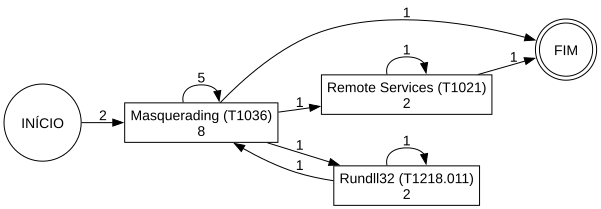

In [98]:
chave = ("lab", "entrada", "18/11/2022")
vertices, arestas = modelos[chave]
grafo = desenhar_modelo(vertices, arestas)

nome_arquivo = "modelo_" + "_".join(chave).replace("/", "-")
salvar_grafo(grafo, nome_arquivo)
salvar_grafo(grafo, nome_arquivo)

print(nome_arquivo)
grafo

# 4.4 Salvando Todos Modelos DFG


lab, entrada, dia 16/11/2022


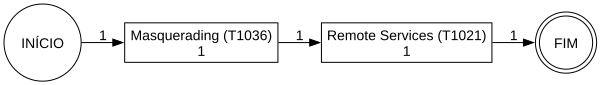


lab, entrada, dia 18/11/2022


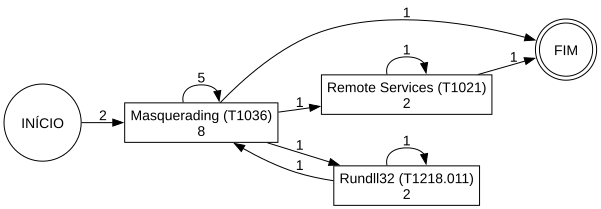


lab, todas, dia 17/11/2022


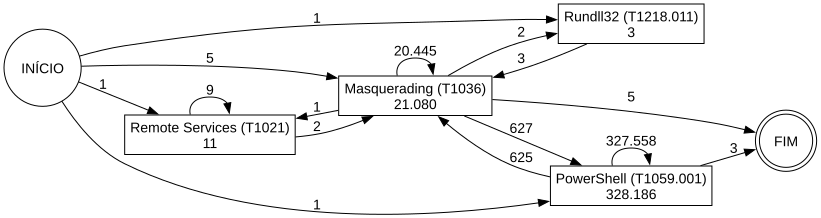


lab, todas, dia 18/11/2022


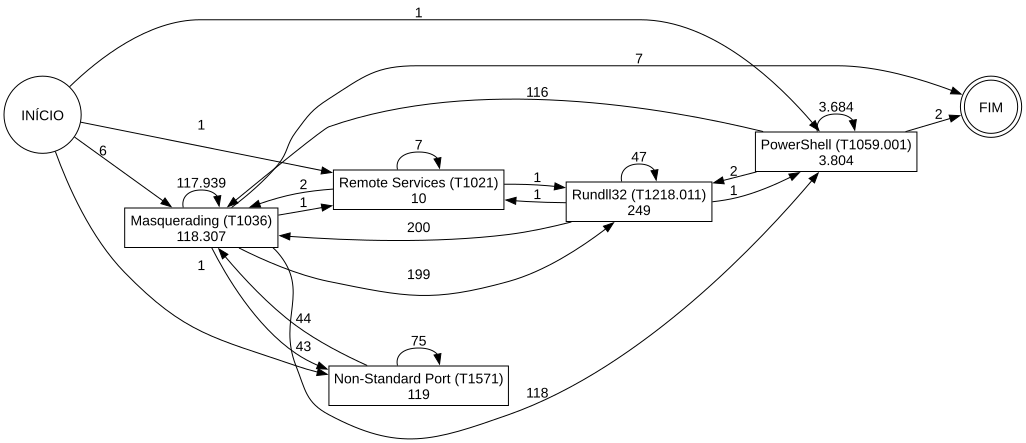


real, entrada, dia 05/07/2022


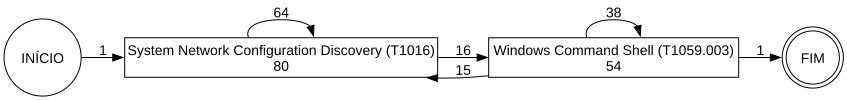


real, todas, dia 05/07/2022


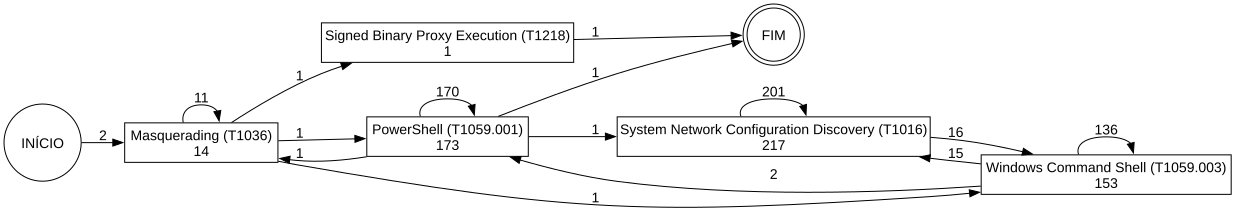


real, todas, dia 06/07/2022


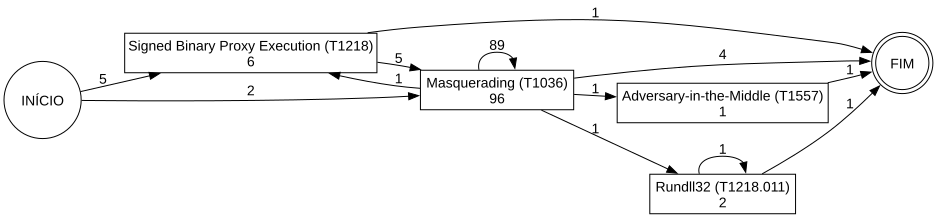


[tempo] gerando todos os grafos de ataque: 2.5s



In [146]:
with cron("gerando todos os grafos de ataque"):
    for chave, (vertices, arestas) in modelos.items():
        grafo = desenhar_modelo(vertices, arestas)
        nome_arquivo = "dfg_" + "_".join(chave).replace("/", "-")
        
        salvar_grafo(grafo, nome_arquivo)
        
        print(f"\n{chave[0]}, {chave[1]}, dia {chave[2]}")
        grafo

# 4.5 Processos SO que disparam regras

In [147]:
chave = ("lab", "entrada", "16/11/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name   proc_name     
T1036      Masquerading     xwin_mobax.exe    1
T1021      Remote Services  svchost.exe       1
Name: count, dtype: int64

In [148]:
chave = ("lab", "entrada", "18/11/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name   proc_name               
T1036      Masquerading     xwin_mobax.exe              4
T1021      Remote Services  svchost.exe                 2
T1036      Masquerading     beacon.exe                  2
T1218.011  Rundll32         rundll32.exe                2
T1036      Masquerading     beacon_2.exe                1
                            beacon_tcp_localhost.exe    1
Name: count, dtype: int64

In [149]:
chave = ("lab", "todas", "17/11/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name   proc_name               
T1059.001  PowerShell       powershell.exe              328186
T1036      Masquerading     beacon.exe                   18803
                            file.exe                      2229
                            microsoft.sharepoint.exe        16
                            xwin_mobax.exe                  12
                            evil1.exe                        9
                            onedrivesetup.exe                7
T1021      Remote Services  gpupdate.exe                     4
                            mottynew.exe                     4
T1218.011  Rundll32         rundll32.exe                     3
T1021      Remote Services  mobaxterm.exe                    2
T1036      Masquerading     wermgr.exe                       2
T1021      Remote Services  svchost.exe                      1
T1036      Masquerading     sharpupgrade.exe                 1
                            gpupdate.exe                     1
Na

In [150]:
chave = ("lab", "todas", "18/11/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name     proc_name               
T1036      Masquerading       beacon.exe                  113168
T1059.001  PowerShell         powershell.exe                3804
T1036      Masquerading       beacon2.exe                   3335
                              file.exe                      1748
T1218.011  Rundll32           rundll32.exe                   249
T1571      Non-Standard Port  svchost.exe                     93
T1036      Masquerading       microsoft.sharepoint.exe        35
                              onedrivesetup.exe               11
T1571      Non-Standard Port  microsoft.sharepoint.exe         8
T1036      Masquerading       xwin_mobax.exe                   7
T1021      Remote Services    gpupdate.exe                     4
T1571      Non-Standard Port  onedrivesetup.exe                4
                              winstore.mobile.exe              4
T1021      Remote Services    mobaxterm.exe                    3
T1571      Non-Standard Port  compa

In [151]:
chave = ("real", "entrada", "05/07/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name                          proc_name   
T1016      System Network Configuration Discovery  nslookup.exe    80
T1059.003  Windows Command Shell                   cmd.exe         54
Name: count, dtype: int64

In [152]:
chave = ("real", "todas", "05/07/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name                          proc_name               
T1016      System Network Configuration Discovery  nslookup.exe                217
T1059.001  PowerShell                              powershell.exe              173
T1059.003  Windows Command Shell                   cmd.exe                     153
T1036      Masquerading                            microsoft.sharepoint.exe     10
                                                   onedrivesetup.exe             3
                                                   sophosupdate.exe              1
T1218      Signed Binary Proxy Execution           msiexec.exe                   1
Name: count, dtype: int64

In [153]:
chave = ("real", "todas", "06/07/2022")
event_log = event_logs[chave[:2]]
event_log[event_log["dia"] == chave[2]].value_counts(["technique", "technique_name", "proc_name"])

technique  technique_name                 proc_name                      
T1036      Masquerading                   printerserviceserverconsole.exe    38
                                          su-repair.exe                      28
                                          msmpeng.exe                        15
                                          sophosupdate.exe                    8
T1218      Signed Binary Proxy Execution  certutil.exe                        5
T1036      Masquerading                   sqlceip.exe                         3
                                          gc_print_data_service.exe           2
T1218.011  Rundll32                       rundll32.exe                        2
T1036      Masquerading                   werfault.exe                        2
T1557      Adversary-in-the-Middle        mcsclient.exe                       1
T1218      Signed Binary Proxy Execution  msiexec.exe                         1
Name: count, dtype: int64

---

# 5. Aside: Outras Agregações Possíveis

> Mesmo pipeline do Sean (filtro de técnica única, DFG, complexidade), muda só noção de caso.

> Universo: os alertas, sem filtro de direção.

# 5.1 Cardinalidade nos alertas
> Quantos valores distintos tem cada candidato a chave de caso?

In [154]:
CHAVES = ["host", "usr", "proc_name", "proc_guid", "tgt_proc_guid", "src_ip", "dst_ip", "technique", "technique_parent"]

cardinalidade = pd.DataFrame({
    cenario: alertas_cenario[CHAVES].nunique() for cenario, alertas_cenario in alertas.items()
})
salvar(cardinalidade.reset_index(names="campo"), OUT / "cardinalidade_alertas")
cardinalidade.T

,host,usr,proc_name,proc_guid,tgt_proc_guid,src_ip,dst_ip,technique,technique_parent
lab,1,10,255,26628,7879,57,154,50,35
real,15,13,295,149496,34318,17,84,53,33


# 5.2 Agregações Candidatas

In [155]:
# nome: (colunas que formam o caso, bool se acrescenta o dia)
AGREGACOES = {
    "ip_origem":     (["src_ip"], True),                  # Sean, um-para-muitos (já feito na seção 3)
    "ip_destino":    (["dst_ip"], True),                  # Sean, muitos-para-um (meio q contido na 3)
    "par_ips":       (["src_ip", "dst_ip"], True),        # canal de comunicação
    "host":          (["host"], True),                    # máquina vítima
    "usuario":       (["host", "usr"], True),             # conta numa máquina
    "programa":      (["host", "proc_name"], True),       # executável (todas as instâncias)
    "processo":      (["host", "proc_guid"], False),      # uma execução (vida própria, sem dia)
    "processo_alvo": (["host", "tgt_proc_guid"], False),  # quem sofre injeção/acesso
}

In [156]:
def construir_log(alertas_cenario, colunas_do_caso, por_dia):
    """Monta o caso e aplica o filtro do Sean, no DuckDB (usa todos os núcleos).
    Devolve a tupla (alertas com chave, casos antes do filtro, event log filtrado)."""
    
    partes_do_caso = colunas_do_caso + (["dia"] if por_dia else [])
    caso_sql = " || '|' || ".join(f'"{coluna}"' for coluna in partes_do_caso)   # ex.: "host" || '|' || "dia"
    tem_chave = " AND ".join(f'"{coluna}" IS NOT NULL' for coluna in colunas_do_caso)

    conn.register("alertas_atual", alertas_cenario)   # o DuckDB enxerga o DataFrame como tabela
    conn.execute(f"""
        CREATE OR REPLACE TEMP TABLE base AS
        SELECT _id, ts, dia, host, proc_name, technique, technique_name, {caso_sql} AS caso
        FROM (
            SELECT *, strftime(ts, '%d/%m/%Y') AS dia
            FROM alertas_atual
            WHERE regexp_matches(technique, '{PADRAO}') AND {tem_chave}
        )
    """)

    n_alertas, casos_antes = conn.execute("SELECT count(*), count(DISTINCT caso) FROM base").fetchone()

    # filtro do Sean: só casos com mais de uma técnica distinta
    event_log = conn.sql("""
        SELECT * FROM base
        WHERE caso IN (
            SELECT caso FROM base GROUP BY caso HAVING count(DISTINCT technique) > 1
        )
        ORDER BY caso, ts, _id
    """).df()

    conn.unregister("alertas_atual")
    return n_alertas, casos_antes, event_log.rename(columns={"caso": "case"})

In [157]:
with cron("event logs de todas as agregações"):
    logs_agregacao = {}   # (cenário, agregação) -> event log filtrado
    linhas = []

    for cenario, alertas_cenario in alertas.items():
        for nome, (colunas_do_caso, por_dia) in AGREGACOES.items():
            n_alertas, casos_antes, event_log = construir_log(alertas_cenario, colunas_do_caso, por_dia)
            logs_agregacao[(cenario, nome)] = event_log

            eventos_por_caso = event_log.groupby("case").size()
            linhas.append({
                "cenario": cenario,
                "agregacao": nome,
                "cobertura_%": round(100 * n_alertas / len(alertas_cenario), 1),
                "casos_antes": casos_antes,
                "casos_depois": event_log["case"].nunique(),
                "eventos_depois": len(event_log),
                "reducao_%": round(100 * (1 - len(event_log) / max(n_alertas, 1)), 1),
                "atividades": event_log["technique"].nunique(),
                "mediana_eventos_por_caso": eventos_por_caso.median() if len(eventos_por_caso) else 0,
            })

tabela_agregacoes = pd.DataFrame(linhas)
salvar(tabela_agregacoes, OUT / "tabela_agregacoes")
tabela_agregacoes


[tempo] event logs de todas as agregações: 12.2s



,cenario,agregacao,cobertura_%,casos_antes,casos_depois,eventos_depois,reducao_%,atividades,mediana_eventos_por_caso
0,lab,ip_origem,68.60,136,41,684904,41.80,5,701.00
1,lab,ip_destino,68.60,359,28,227502,80.70,4,22.50
2,lab,par_ips,68.60,447,28,226493,80.70,4,19.50
3,lab,host,100.00,10,10,1713654,0.00,49,151603.00
4,lab,usuario,95.50,53,49,1637043,0.00,48,8439.00
5,lab,programa,100.00,1398,876,1531347,10.60,45,51.50
6,lab,processo,100.00,26628,7404,1585073,7.50,43,7.00
7,lab,processo_alvo,4.50,7879,315,18816,75.40,4,4.00
8,real,ip_origem,0.30,96,24,967,42.30,7,16.00
9,real,ip_destino,0.30,185,12,422,74.80,5,5.00


# 5.3 Complexidade por agregação
> Como no Sean: modelo do dia com mais eventos. Alguma agregação gera modelo complexo (e aciona o clustering)?

In [158]:
modelos_agregacao = {}   # (cenário, agregação) -> (vértices, arestas)
linhas = []

for (cenario, nome), event_log in logs_agregacao.items():
    if event_log.empty:
        continue
    dia_mais_eventos = event_log["dia"].value_counts().idxmax()
    log_do_dia = event_log[event_log["dia"] == dia_mais_eventos]

    vertices, arestas = descobrir_modelo(log_do_dia)
    n_vertices = len(vertices) + 2
    n_arestas = len(arestas)
    modelos_agregacao[(cenario, nome)] = (vertices, arestas)
    linhas.append({
        "cenario": cenario, "agregacao": nome, "dia": dia_mais_eventos,
        "casos": log_do_dia["case"].nunique(),
        "vertices": n_vertices, "arestas": n_arestas,
        "simplicidade": round(n_vertices / n_arestas, 3),
        "limiar_ts": round(limiar_ts(n_vertices), 3),
        "complexo": eh_complexo(n_vertices, n_arestas),
    })

tabela_complexidade = pd.DataFrame(linhas)
salvar(tabela_complexidade, OUT / "tabela_complexidade")
tabela_complexidade.sort_values(by="complexo")

,cenario,agregacao,dia,casos,vertices,arestas,simplicidade,limiar_ts,complexo
0,lab,ip_origem,17/11/2022,8,6,15,0.40,0.15,False
1,lab,ip_destino,18/11/2022,6,6,16,0.38,0.15,False
2,lab,par_ips,18/11/2022,7,6,17,0.35,0.15,False
7,lab,processo_alvo,16/11/2022,57,6,21,0.29,0.15,False
8,real,ip_origem,05/07/2022,2,7,15,0.47,0.17,False
9,real,ip_destino,05/07/2022,3,5,11,0.46,0.12,False
10,real,par_ips,05/07/2022,3,5,11,0.46,0.12,False
15,real,processo_alvo,08/07/2022,623,7,25,0.28,0.17,False
3,lab,host,17/11/2022,1,45,580,0.08,0.98,True
4,lab,usuario,17/11/2022,5,44,520,0.09,0.96,True


# 5.4 Casos e suas sequências (IPs e Processos)

In [159]:
def resumo_casos(chave, max_trechos=15):
    """Para um modelo (cenário, direção, dia): cada caso com sua sequência de técnica + processo.
    Repetições seguidas viram 'xN'."""
    event_log = event_logs[chave[:2]]
    log_do_dia = event_log[event_log["dia"] == chave[2]]

    for caso, eventos_do_caso in log_do_dia.groupby("case", sort=False):
        passos = (eventos_do_caso["technique"] + "  " + eventos_do_caso["proc_name"]).tolist()

        trechos = []   # [passo, quantas vezes seguidas]
        for passo in passos:
            if trechos and trechos[-1][0] == passo:
                trechos[-1][1] += 1
            else:
                trechos.append([passo, 1])

        destinos = sorted(eventos_do_caso["dst_ip"].unique())
        print(f"\n{caso}  | {len(eventos_do_caso):,} eventos | destinos: {destinos[:5]}")
        for passo, vezes in trechos[:max_trechos]:
            print(f"    {passo}" + (f"  x{vezes:,}" if vezes > 1 else ""))
        if len(trechos) > max_trechos:
            print(f"    ... (+{len(trechos) - max_trechos} trechos)")

In [160]:
resumo_casos(("lab", "entrada", "18/11/2022"))


10.10.117.130|18/11/2022  | 3 eventos | destinos: ['10.10.117.130']
    T1036  xwin_mobax.exe
    T1021  svchost.exe  x2

127.0.0.1|18/11/2022  | 9 eventos | destinos: ['127.0.0.1']
    T1036  xwin_mobax.exe  x3
    T1036  beacon.exe  x2
    T1218.011  rundll32.exe  x2
    T1036  beacon_2.exe
    T1036  beacon_tcp_localhost.exe


In [161]:
resumo_casos(("lab", "todas", "18/11/2022"))


10.10.117.130|18/11/2022  | 54 eventos | destinos: ['10.10.117.1', '10.10.117.128', '10.10.117.129', '10.10.117.130', '10.10.117.143']
    T1036  beacon.exe  x6
    T1036  beacon2.exe  x3
    T1036  xwin_mobax.exe
    T1021  gpupdate.exe
    T1021  svchost.exe
    T1021  gpupdate.exe  x3
    T1036  beacon2.exe  x3
    T1218.011  rundll32.exe  x6
    T1021  svchost.exe
    T1218.011  rundll32.exe  x14
    T1036  beacon.exe  x15

10.10.234.129|18/11/2022  | 165 eventos | destinos: ['10.10.234.128', '10.10.234.130']
    T1021  mottynew.exe
    T1021  mobaxterm.exe  x3
    T1036  beacon.exe  x161

127.0.0.1|18/11/2022  | 18 eventos | destinos: ['127.0.0.1']
    T1036  xwin_mobax.exe  x6
    T1036  beacon.exe
    T1059.001  powershell.exe
    T1036  beacon.exe
    T1059.001  powershell.exe
    T1218.011  rundll32.exe
    T1036  beacon.exe  x2
    T1218.011  rundll32.exe
    T1059.001  powershell.exe
    T1036  beacon_2.exe
    T1036  beacon_http.exe
    T1036  beacon_tcp_localhost.exe

192

---